### Creating Training and validation Graph

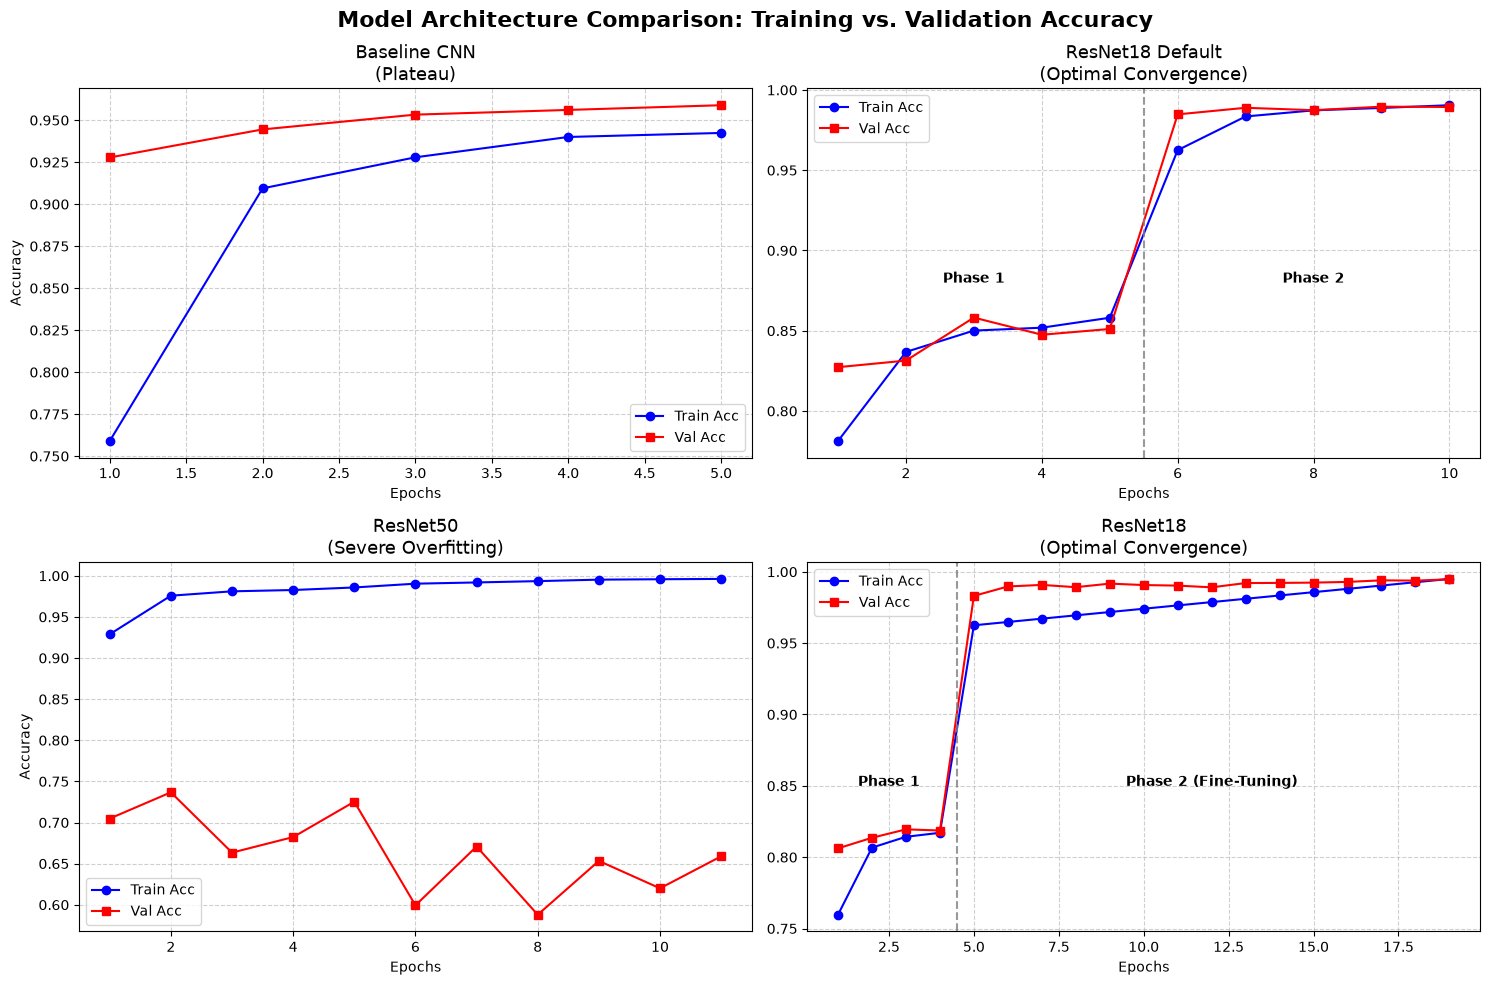

In [4]:
import matplotlib.pyplot as plt
import numpy as np

def plot_all_models_comparison():
    # 1. Baseline CNN Data (5 Epochs)
    cnn_epochs = np.arange(1, 6)
    cnn_train = [0.7590, 0.9094, 0.9279, 0.9400, 0.9424]
    cnn_val = [0.9278, 0.9445, 0.9533, 0.9561, 0.9589]

    # 2. Baseline Transfer Model Data (10 Epochs: 5 Phase 1 + 5 Phase 2)
    r18_epochs_train1 = np.arange(1, 11) # Fixed: Changed to 11 to match the 10 data points
    r18_train_1 = [0.7813, 0.8368, 0.8501, 0.8519, 0.8581, 
                   0.9625, 0.9835, 0.9873, 0.9888, 0.9905]
    r18_val_1 = [0.8273, 0.8314, 0.8582, 0.8475, 0.8511,
                 0.9848, 0.9889, 0.9874, 0.9896, 0.9894]

    # 3. ResNet50 Data (11 Epochs - Overfitting Example)
    r50_epochs = np.arange(1, 12)
    r50_train = [0.9289, 0.9758, 0.9811, 0.9827, 0.9858, 0.9904, 0.9919, 0.9935, 0.9953, 0.9958, 0.9962]
    r50_val = [0.7048, 0.7367, 0.6634, 0.6823, 0.7253, 0.5993, 0.6708, 0.5879, 0.6533, 0.6200, 0.6589]

    # 4. ResNet18 Two-Stage Data (4 Frozen + 15 Unfrozen)
    r18_epochs = np.arange(1, 20)
    r18_train = [0.7597, 0.8067, 0.8143, 0.8171] + list(np.linspace(0.9625, 0.9950, 15))
    r18_val = [0.8062, 0.8136, 0.8195, 0.8187, 0.9831, 0.9897, 0.9908, 0.9892, 0.9917, 
               0.9907, 0.9903, 0.9891, 0.9921, 0.9922, 0.9924, 0.9929, 0.9940, 0.9938, 0.9947]

    # Create a 2x2 Subplot Figure (Fixed figsize height from 5 to 10 for better proportions)
    fig, axes = plt.subplots(2, 2, figsize=(15, 10), sharey=False)
    fig.suptitle('Model Architecture Comparison: Training vs. Validation Accuracy', fontsize=16, weight='bold')

    # Plot 1: Baseline CNN
    axes[0, 0].plot(cnn_epochs, cnn_train, 'bo-', label='Train Acc')
    axes[0, 0].plot(cnn_epochs, cnn_val, 'rs-', label='Val Acc')
    axes[0, 0].set_title('Baseline CNN\n(Plateau)', fontsize=13)
    axes[0, 0].set_xlabel('Epochs')
    axes[0, 0].set_ylabel('Accuracy')
    axes[0, 0].grid(True, linestyle='--', alpha=0.6)
    axes[0, 0].legend()

    # Plot 2: ResNet18 Default
    axes[0, 1].plot(r18_epochs_train1, r18_train_1, 'bo-', label='Train Acc')
    axes[0, 1].plot(r18_epochs_train1, r18_val_1, 'rs-', label='Val Acc')
    axes[0, 1].axvline(x=5.5, color='gray', linestyle='--', alpha=0.8) # Adjusted divider line
    axes[0, 1].text(3, 0.88, 'Phase 1', ha='center', fontsize=10, weight='bold')
    axes[0, 1].text(8, 0.88, 'Phase 2', ha='center', fontsize=10, weight='bold') # Fixed off-chart text
    axes[0, 1].set_title('ResNet18 Default\n(Optimal Convergence)', fontsize=13)
    axes[0, 1].set_xlabel('Epochs')
    axes[0, 1].grid(True, linestyle='--', alpha=0.6)
    axes[0, 1].legend()

    # Plot 3: ResNet50
    axes[1, 0].plot(r50_epochs, r50_train, 'bo-', label='Train Acc')
    axes[1, 0].plot(r50_epochs, r50_val, 'rs-', label='Val Acc')
    axes[1, 0].set_title('ResNet50\n(Severe Overfitting)', fontsize=13)
    axes[1, 0].set_xlabel('Epochs')
    axes[1, 0].set_ylabel('Accuracy')
    axes[1, 0].grid(True, linestyle='--', alpha=0.6)
    axes[1, 0].legend()

    # Plot 4: ResNet18 Fine-Tuned
    axes[1, 1].plot(r18_epochs, r18_train, 'bo-', label='Train Acc')
    axes[1, 1].plot(r18_epochs, r18_val, 'rs-', label='Val Acc')
    axes[1, 1].axvline(x=4.5, color='gray', linestyle='--', alpha=0.8)
    axes[1, 1].text(2.5, 0.85, 'Phase 1', ha='center', fontsize=10, weight='bold')
    axes[1, 1].text(12, 0.85, 'Phase 2 (Fine-Tuning)', ha='center', fontsize=10, weight='bold')
    axes[1, 1].set_title('ResNet18\n(Optimal Convergence)', fontsize=13)
    axes[1, 1].set_xlabel('Epochs')
    axes[1, 1].grid(True, linestyle='--', alpha=0.6)
    axes[1, 1].legend()

    plt.tight_layout()
    plt.savefig('model_comparison_accuracy.png', dpi=300, bbox_inches='tight')
    plt.show()

plot_all_models_comparison()

### Creating Validation and Testing Graph for each model

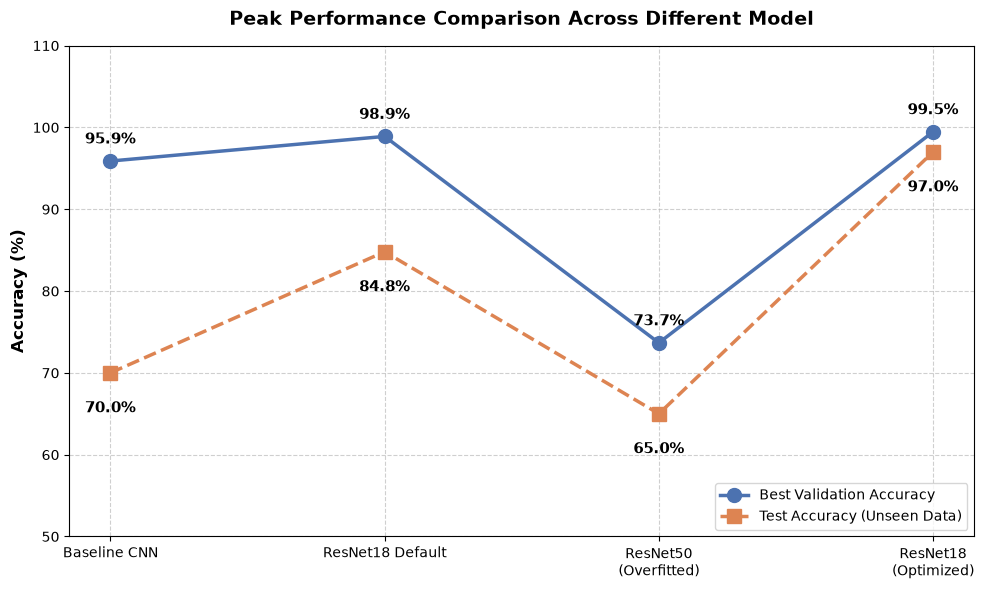

In [9]:
import matplotlib.pyplot as plt
import numpy as np

def plot_best_scores():
    # Model names
    models = ['Baseline CNN', 'ResNet18 Default', 'ResNet50\n(Overfitted)', 'ResNet18\n(Optimized)']
    
    # Highest recorded Validation and Test scores (in percentages)
    # Note: Baseline test is approx 70%, ResNet50 is lower than baseline (~65%)
    val_scores = [95.89, 98.9, 73.67, 99.47]
    test_scores = [70.00, 84.80, 65.00, 97.00] 
    
    x = np.arange(len(models))  # Label locations
    width = 0.35  # Bar width

    fig, ax = plt.subplots(figsize=(10, 6))
    
    # Plot as scatter points connected by lines
    ax.plot(models, val_scores, marker='o', markersize=10, linestyle='-', linewidth=2.5, 
            color='#4C72B0', label='Best Validation Accuracy')
    ax.plot(models, test_scores, marker='s', markersize=10, linestyle='--', linewidth=2.5, 
            color='#DD8452', label='Test Accuracy (Unseen Data)')

    # Formatting and labels
    ax.set_ylabel('Accuracy (%)', fontsize=12, weight='bold')
    ax.set_title('Peak Performance Comparison Across Different Model', fontsize=14, weight='bold', pad=15)
    ax.set_ylim(50, 110) # Set limits to give breathing room for annotations
    ax.legend(loc='lower right')

    # Function to attach a text label next to each point
    def add_labels(x_data, y_data, offset):
        for i in range(len(x_data)):
            ax.annotate(f'{y_data[i]:.1f}%',
                        xy=(i, y_data[i]),
                        xytext=(0, offset),  # Vertical offset
                        textcoords="offset points",
                        ha='center', va='bottom' if offset > 0 else 'top', 
                        fontsize=11, weight='bold')

    # Apply the labels (Validation slightly above the dot, Test slightly below)
    add_labels(models, test_scores, -20)
    add_labels(models, val_scores, 10)

    # Clean up the background
    ax.grid(True, linestyle='--', alpha=0.6)
    
    plt.tight_layout()
    plt.savefig('peak_performance_scatter_line.png', dpi=300, bbox_inches='tight')
    plt.show()

plot_best_scores()

### Creating Confusion Model for Best Model

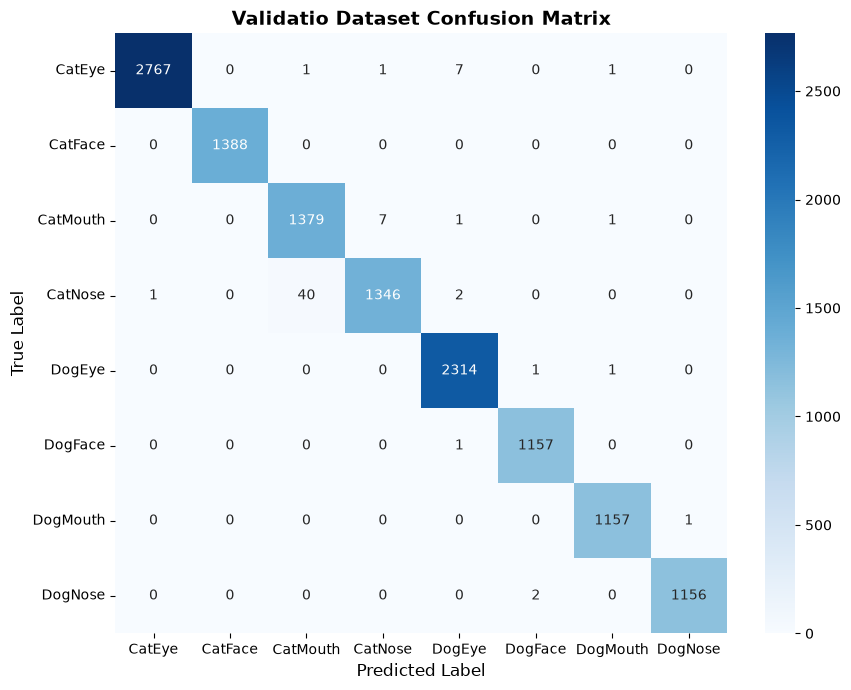

In [13]:
import torch
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
from datacleaner_v2 import build_training_dataloaders


# Ensure model is in evaluation mode
from transfermodel import TransferResNet

train_loader, val_loader = build_training_dataloaders(
    csv_path='./raw_data/train_labels_strId.csv', 
    img_dir='./raw_data/train/train', 
    batch_size=32
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = TransferResNet(num_classes=8, freeze_features=False).to(device)

model.load_state_dict(torch.load('./outputs/transfer_model_v4_phase2.pth', map_location=device))
model.to(device)
model.eval()

y_true = []
y_pred = []

# Disable gradient calculation for inference
with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)
        labels = labels.to(device)
        
        outputs = model(images)
        _, predicted = torch.max(outputs, 1)
        
        y_true.extend(labels.cpu().numpy())
        y_pred.extend(predicted.cpu().numpy())

# Generate the actual confusion matrix
cm = confusion_matrix(y_true, y_pred)
classes = ['CatEye', 'CatFace', 'CatMouth', 'CatNose', 'DogEye', 'DogFace', 'DogMouth', 'DogNose']

# Plot the authentic matrix
plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=classes, yticklabels=classes)
plt.title('Validation Dataset Confusion Matrix', fontsize=14, weight='bold')
plt.xlabel('Predicted Label', fontsize=12)
plt.ylabel('True Label', fontsize=12)
plt.tight_layout()
plt.show()

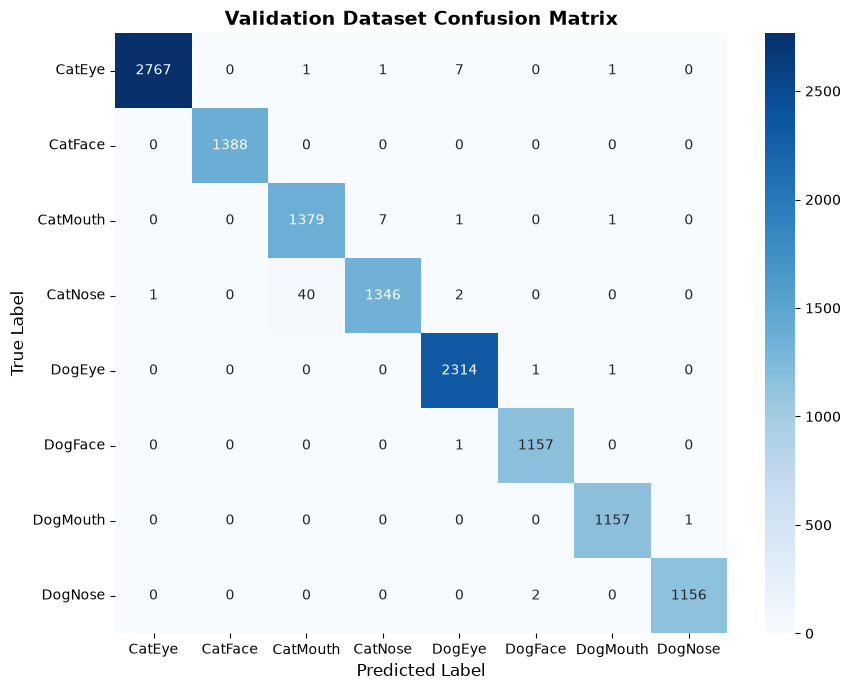

In [14]:
# Generate the actual confusion matrix
cm = confusion_matrix(y_true, y_pred)
classes = ['CatEye', 'CatFace', 'CatMouth', 'CatNose', 'DogEye', 'DogFace', 'DogMouth', 'DogNose']

# Plot the authentic matrix
plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=classes, yticklabels=classes)
plt.title('Validation Dataset Confusion Matrix', fontsize=14, weight='bold')
plt.xlabel('Predicted Label', fontsize=12)
plt.ylabel('True Label', fontsize=12)
plt.tight_layout()
plt.show()